# Reto AgroCebada FIRA 2026
## Libreta 01 - Calidad y Contexto Agronomico

> *"Antes de predecir el rendimiento, necesitamos entender que miden realmente nuestros satelites, que limitaciones tiene cada sensor y como se distribuyen las parcelas en el territorio."*

### Seccion del Reporte que alimenta esta libreta
| Seccion del Reporte | Contenido generado aqui |
|---|---|
| **Introduccion** | Descripcion del dataset, ventana temporal y distribucion geografica |
| **Justificacion** | Diagnostico de calidad de sensores y necesidad de fusion satelital |

### Objetivos de esta libreta
1. Cargar y validar la estructura completa del `DataSet.zip` entregado por FIRA.
2. Analizar la distribucion espacial de las 197 parcelas (entrenamiento vs prediccion).
3. Diagnosticar la calidad de las observaciones satelitales (Sentinel-2, Landsat, Planet).
4. Generar el **mapa de calor de cobertura mensual** que demuestra por que ciertos meses criticos requieren fusion de satelites.

### Alcance temporal
Ciclo agricola **abril-octubre de 2025**. Este analisis es retrospectivo sobre el ciclo completo, no constituye un pronostico anticipado antes de cosecha.

In [1]:
# ============================================================
# 1. CONFIGURACION MAESTRA Y ENTORNO
# ============================================================
!pip install -q geopandas shapely pyproj pyshp rasterio rasterstats optuna shap

import os
import json
import zipfile
import shutil
import hashlib
import warnings
from pathlib import Path
from io import BytesIO

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Estilo visual para las graficas del reporte
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

EN_COLAB = True  # Cambiar a False si el evaluador lo corre en su PC local (GitHub)

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/Reto_AgroCebada_2026')
else:
    BASE = Path(os.getcwd())

CARPETAS = {
    'raw':           BASE / 'data' / 'raw',
    '01_calidad':    BASE / 'data' / '01_calidad',
    '02_fenologia':  BASE / 'data' / '02_fenologia',
    '03_validacion': BASE / 'data' / '03_validacion',
    '04_shap':       BASE / 'data' / '04_shap',
    '05_final':      BASE / 'data' / '05_final',
    'models':        BASE / 'models',
    'artifacts':     BASE / 'artifacts',
    'reports':       BASE / 'reports',
}

for carpeta in CARPETAS.values():
    carpeta.mkdir(parents=True, exist_ok=True)

SALIDA = CARPETAS['01_calidad']
CARPETA_DATOS = CARPETAS['raw'] / 'extraido'

# Parametros del proyecto
INICIO = '2025-04-01'
FIN = '2025-10-31'
MESES = [f'2025-{m:02d}' for m in range(4, 11)]
NOMBRES_MESES = ['Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre']

# --- Funciones auxiliares ---
def guardar_csv(df, nombre, carpeta='raw'):
    """Guarda un DataFrame en la carpeta indicada."""
    ruta = CARPETAS[carpeta] / nombre
    df.to_csv(ruta, index=False, encoding='utf-8-sig')
    print(f"[OK] Guardado: {ruta}")
    return ruta

def cargar_csv(nombre, carpeta='raw', **kwargs):
    """Carga un CSV desde la carpeta indicada."""
    ruta = CARPETAS[carpeta] / nombre
    assert ruta.exists(), f"[ERROR] No existe: {ruta}"
    df = pd.read_csv(ruta, **kwargs)
    print(f"[OK] Cargado: {nombre} ({df.shape[0]} filas x {df.shape[1]} cols)")
    return df

def guardar_json(obj, nombre, carpeta='raw'):
    ruta = CARPETAS[carpeta] / nombre
    with open(ruta, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)
    print(f"[OK] Guardado: {ruta}")
    return ruta

def cargar_json(nombre, carpeta='raw'):
    ruta = CARPETAS[carpeta] / nombre
    assert ruta.exists(), f"[ERROR] No existe: {ruta}"
    with open(ruta, 'r', encoding='utf-8') as f:
        return json.load(f)

def guardar_figura(fig, nombre, carpeta='reports'):
    ruta = CARPETAS[carpeta] / nombre
    fig.savefig(ruta, dpi=200, bbox_inches='tight')
    print(f"[OK] Grafico guardado: {ruta}")
    return ruta

def guardar_modelo(modelo, nombre):
    import joblib
    ruta = CARPETAS['models'] / nombre
    joblib.dump(modelo, ruta)
    print(f"[OK] Modelo guardado: {ruta}")
    return ruta

def cargar_modelo(nombre):
    import joblib
    ruta = CARPETAS['models'] / nombre
    assert ruta.exists(), f"[ERROR] No existe: {ruta}"
    return joblib.load(ruta)

def listar_archivos(carpeta='raw'):
    """Lista los archivos disponibles en una carpeta."""
    ruta = CARPETAS[carpeta]
    archivos = sorted(ruta.iterdir()) if ruta.exists() else []
    if not archivos:
        print(f"Carpeta '{carpeta}' vacia")
    else:
        print(f"Carpeta '{carpeta}': {len(archivos)} archivos")
        for a in archivos:
            tamano = a.stat().st_size
            unidad = 'MB' if tamano > 1e6 else 'KB' if tamano > 1e3 else 'B'
            valor = tamano / 1e6 if tamano > 1e6 else tamano / 1e3 if tamano > 1e3 else tamano
            print(f"   - {a.name} ({valor:.1f} {unidad})")
    return archivos

def sha256(ruta):
    """Calcula hash SHA-256 de un archivo."""
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b''):
            h.update(chunk)
    return h.hexdigest()

print("=" * 60)
print("ESTRUCTURA DE DIRECTORIOS LISTA")
print("=" * 60)
for nombre, ruta in CARPETAS.items():
    print(f"   {nombre:>15}: {ruta}")
print(f"\nVentana temporal: {INICIO} a {FIN}")
print(f"Directorio de salida: {SALIDA}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 15.7 MB/s eta 0:00:00
Mounted at /content/drive
ESTRUCTURA DE DIRECTORIOS LISTA
               raw: /content/drive/MyDrive/Reto_AgroCebada_2026/data/raw
        01_calidad: /content/drive/MyDrive/Reto_AgroCebada_2026/data/01_calidad
      02_fenologia: /content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia
     03_validacion: /content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion
           04_shap: /content/drive/MyDrive/Reto_AgroCebada_2026/data/04_shap
          05_final: /content/drive/MyDrive/Reto_AgroCebada_2026/data/05_final
            models: /content/drive/MyDrive/Reto_AgroCebada_2026/models
         artifacts: /content/drive/MyDrive/Reto_AgroCebada_2026/artifacts
           reports: /content/drive/MyDrive/Reto_AgroCebada_2026/reports

Ventana temporal: 2025-04-01 a 2025-10-31
Directorio de salida: /content/drive/MyDrive/Ret

In [2]:
# ============================================================
# 2. EXTRACCION O SUBIDA DEL DATASET ORIGINAL (SOLO SI FALTA)
# ============================================================
RAW = CARPETA_DATOS / 'DATASET_RETO_AGRO_2026'

if not RAW.exists():
    destino_zip = CARPETAS['raw'] / 'DataSet.zip'
    if not destino_zip.exists() and EN_COLAB:
        from google.colab import files
        print("Selecciona el archivo DataSet.zip:")
        subidos = files.upload()
        for nombre, contenido in subidos.items():
            destino_zip = CARPETAS['raw'] / nombre
            with open(destino_zip, 'wb') as f:
                f.write(contenido)
            print(f"[OK] Subido a Drive: {destino_zip}")

    if destino_zip.exists():
        CARPETA_DATOS.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(destino_zip, 'r') as z:
            z.extractall(CARPETA_DATOS)
        print(f"[OK] Extraido en: {CARPETA_DATOS}")
        for f in sorted(CARPETA_DATOS.iterdir()):
            print(f"   - {f.name}")
else:
    print(f"[OK] Dataset original encontrado en: {RAW}")

Selecciona el archivo DataSet.zip:


Saving DataSet.zip to DataSet.zip
[OK] Subido a Drive: /content/drive/MyDrive/Reto_AgroCebada_2026/data/raw/DataSet.zip
[OK] Extraido en: /content/drive/MyDrive/Reto_AgroCebada_2026/data/raw/extraido
   - DATASET_RETO_AGRO_2026


In [3]:
# ============================================================
# 3. CARGA Y VALIDACION DE LA TABLA MAESTRA DE PARCELAS
# ============================================================
ruta_maestro = RAW / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv'
df_maestro = pd.read_csv(ruta_maestro)

# Limpieza de identificadores y eliminacion de columnas vacias
df_maestro['ID_POLIGONO'] = df_maestro['ID_POLIGONO'].astype(str).str.strip()
columnas_vacias = [c for c in df_maestro.columns if c.startswith('Unnamed:') and df_maestro[c].isna().all()]
if columnas_vacias:
    df_maestro = df_maestro.drop(columns=columnas_vacias)
    print(f"Columnas vacias eliminadas: {columnas_vacias}")

# Validaciones de integridad
assert len(df_maestro) == 197, f"Se esperaban 197 parcelas, se encontraron {len(df_maestro)}"
assert df_maestro['ID_POLIGONO'].is_unique, "Hay IDs duplicados"
assert set(df_maestro['CONJUNTO'].unique()) == {'ENTRENAMIENTO', 'PREDICCION'}

# Separacion del reto
df_entrenamiento = df_maestro[df_maestro['CONJUNTO'] == 'ENTRENAMIENTO'].copy()
df_prediccion = df_maestro[df_maestro['CONJUNTO'] == 'PREDICCION'].copy()

print("=" * 60)
print("TABLA MAESTRA DE PARCELAS")
print("=" * 60)
print(f"Total de parcelas:       {len(df_maestro)}")
print(f"Entrenamiento (con y):   {len(df_entrenamiento)} ({len(df_entrenamiento)/len(df_maestro)*100:.1f}%)")
print(f"Prediccion (sin y):      {len(df_prediccion)} ({len(df_prediccion)/len(df_maestro)*100:.1f}%)")
print("\nArea (hectareas):")
print(f"   Media:          {df_maestro['AREA_HA'].mean():.2f} ha")
print(f"   Mediana:        {df_maestro['AREA_HA'].median():.2f} ha")
print(f"   Minimo:         {df_maestro['AREA_HA'].min():.2f} ha")
print(f"   Maximo:         {df_maestro['AREA_HA'].max():.2f} ha")
print("\nRendimiento (t/ha) - solo entrenamiento:")
print(f"   Media:          {df_entrenamiento['RENDIMIENTO_T_HA'].mean():.2f} t/ha")
print(f"   Mediana:        {df_entrenamiento['RENDIMIENTO_T_HA'].median():.2f} t/ha")
print(f"   Desv. Estandar: {df_entrenamiento['RENDIMIENTO_T_HA'].std():.2f} t/ha")
print(f"   Minimo:         {df_entrenamiento['RENDIMIENTO_T_HA'].min():.2f} t/ha")
print(f"   Maximo:         {df_entrenamiento['RENDIMIENTO_T_HA'].max():.2f} t/ha")

# Verificar que prediccion no tenga rendimiento
assert df_prediccion['RENDIMIENTO_T_HA'].isna().all(), "Las parcelas de prediccion NO deben tener rendimiento"
print("\n[OK] Validacion: Las 59 parcelas de prediccion NO tienen rendimiento conocido")

Columnas vacias eliminadas: ['Unnamed: 4']
TABLA MAESTRA DE PARCELAS
Total de parcelas:       197
Entrenamiento (con y):   138 (70.1%)
Prediccion (sin y):      59 (29.9%)

Area (hectareas):
   Media:          6.60 ha
   Mediana:        5.46 ha
   Minimo:         0.35 ha
   Maximo:         64.30 ha

Rendimiento (t/ha) - solo entrenamiento:
   Media:          3.96 t/ha
   Mediana:        4.34 t/ha
   Desv. Estandar: 0.85 t/ha
   Minimo:         2.00 t/ha
   Maximo:         5.59 t/ha

[OK] Validacion: Las 59 parcelas de prediccion NO tienen rendimiento conocido


In [5]:
# ============================================================
# 4. CARGA DE LA CAPA ESPACIAL (SHAPEFILE)
# ============================================================
archivo_parcelas_zip = RAW / 'Parcelas_Reto_AGC_CONJUNTO_70_30.zip'
CARPETA_PARCELAS = CARPETA_DATOS / 'parcelas'
CARPETA_PARCELAS.mkdir(exist_ok=True)

if archivo_parcelas_zip.exists():
    with zipfile.ZipFile(archivo_parcelas_zip, 'r') as z:
        z.extractall(CARPETA_PARCELAS)
    print("[OK] ZIP de parcelas extraido")

archivos_shp = list(CARPETA_PARCELAS.glob('*.shp'))
if not archivos_shp:
    archivos_shp = list(CARPETA_PARCELAS.rglob('*.shp'))
assert len(archivos_shp) == 1, f"Se esperaba un archivo .shp, se encontraron {len(archivos_shp)}"
ruta_shp = archivos_shp[0]

gdf_parcelas = gpd.read_file(ruta_shp)

# Normalizar el nombre de la columna ID
columnas_id = [c for c in gdf_parcelas.columns if 'ID_POL' in c.upper()]
if columnas_id:
    col_id_shape = columnas_id[0]
else:
    col_id_shape = [c for c in gdf_parcelas.columns if c.lower() != 'geometry'][0]

gdf_parcelas = gdf_parcelas.rename(columns={col_id_shape: 'ID_POLIGONO'})
gdf_parcelas['ID_POLIGONO'] = gdf_parcelas['ID_POLIGONO'].astype(str).str.strip()

print("=" * 60)
print("CAPA ESPACIAL DE PARCELAS")
print("=" * 60)
print(f"Archivo:                {ruta_shp.name}")
print(f"Sistema de Coordenadas: {gdf_parcelas.crs}")
print(f"Numero de parcelas:     {len(gdf_parcelas)}")
print(f"Columnas de atributos:  {list(gdf_parcelas.columns)}")

# Extraer coordenadas del centroide
if gdf_parcelas.crs is None:
    print("[AVISO] Sin CRS definido, asumiendo WGS84")
    gdf_parcelas = gdf_parcelas.set_crs('EPSG:4326')

gdf_wgs84 = gdf_parcelas.to_crs(epsg=4326)
gdf_parcelas['longitud'] = gdf_wgs84.geometry.centroid.x
gdf_parcelas['latitud'] = gdf_wgs84.geometry.centroid.y

# Calcular area en hectareas desde la geometria (ITRF2008 LCC Mexico)
gdf_metrico = gdf_parcelas.to_crs(epsg=6372)
gdf_parcelas['area_ha_geometria'] = gdf_metrico.geometry.area / 10000

print("\nCoordenadas de los centroides:")
print(f"   Latitud:  {gdf_parcelas['latitud'].min():.4f} a {gdf_parcelas['latitud'].max():.4f}")
print(f"   Longitud: {gdf_parcelas['longitud'].min():.4f} a {gdf_parcelas['longitud'].max():.4f}")

[OK] ZIP de parcelas extraido
CAPA ESPACIAL DE PARCELAS
Archivo:                Parcelas_Reto_AGC_CONJUNTO.shp
Sistema de Coordenadas: EPSG:4326
Numero de parcelas:     197
Columnas de atributos:  ['Cultivo', 'ID_POLIGONO', 'área_ha', 'Municipio', 'Estado', 'CONJUNTO', 'geometry']

Coordenadas de los centroides:
   Latitud:  19.5257 a 19.9814
   Longitud: -98.6115 a -98.2002


In [6]:
# ============================================================
# 5. DISTRIBUCION GEOGRAFICA: ESTADO Y CONJUNTO
# ============================================================
df_geo = df_maestro.merge(
    gdf_parcelas[['ID_POLIGONO', 'Estado', 'Municipio', 'latitud', 'longitud', 'area_ha_geometria']],
    on='ID_POLIGONO',
    how='left'
)

print("=" * 60)
print("DISTRIBUCION POR ESTADO")
print("=" * 60)
tabla_estado = pd.crosstab(df_geo['Estado'], df_geo['CONJUNTO'], margins=True)
print(tabla_estado)

print("\n" + "=" * 60)
print("DISTRIBUCION POR MUNICIPIO")
print("=" * 60)
tabla_municipio = pd.crosstab([df_geo['Estado'], df_geo['Municipio']], df_geo['CONJUNTO'], margins=True)
print(tabla_municipio)

# Verificar que la geometria coincide con la tabla
comparacion_area = df_geo[['AREA_HA', 'area_ha_geometria']].dropna()
correlacion_area = comparacion_area['AREA_HA'].corr(comparacion_area['area_ha_geometria'])
diferencia_relativa = ((comparacion_area['AREA_HA'] - comparacion_area['area_ha_geometria']).abs() / comparacion_area['AREA_HA']).mean()

print("\nVerificacion de areas:")
print(f"   Correlacion entre tabla y geometria: {correlacion_area:.4f}")
print(f"   Diferencia relativa media:           {diferencia_relativa*100:.2f}%")
if correlacion_area > 0.99:
    print("   [OK] Las areas coinciden entre la tabla y la geometria")
else:
    print("   [AVISO] Discrepancia en las areas, revisar")

DISTRIBUCION POR ESTADO
CONJUNTO  ENTRENAMIENTO  PREDICCION  All
Estado                                  
Hidalgo              36          15   51
Puebla               71          29  100
Tlaxcala             31          15   46
All                 138          59  197

DISTRIBUCION POR MUNICIPIO
CONJUNTO                                ENTRENAMIENTO  PREDICCION  All
Estado   Municipio                                                    
Hidalgo  Almoloya                                  10           4   14
         Apan                                       1           0    1
         Cuautepec de Hinojosa                      5           4    9
         Emiliano Zapata                            3           0    3
         Singuilucan                               16           7   23
         Tepeapulco                                 1           0    1
Puebla   Chignahuapan                              71          29  100
Tlaxcala Calpulalpan                               30          

In [7]:
# ============================================================
# 6. CARGA DE LAS OBSERVACIONES SATELITALES
# ============================================================
# --- Dataset BASICO (Sentinel-2 y Landsat) ---
ruta_basico = RAW / 'Conjunto_datos_BASICO_AgroCebada2026.csv'
df_basico = pd.read_csv(ruta_basico, dtype={'ID_POLIGONO': str})
df_basico['ID_POLIGONO'] = df_basico['ID_POLIGONO'].str.strip()
df_basico['fecha_captura'] = pd.to_datetime(df_basico['fecha_captura'], format='%d/%m/%Y')
df_basico['mes'] = df_basico['fecha_captura'].dt.to_period('M').astype(str)

# --- Dataset PRO (Planet) ---
ruta_pro = RAW / 'Conjunto_datos_PRO_AgroCebada.csv'
df_pro = pd.read_csv(ruta_pro, dtype={'ID_POLIGONO': str})
df_pro['ID_POLIGONO'] = df_pro['ID_POLIGONO'].str.strip()
df_pro['fecha_captura'] = pd.to_datetime(df_pro['fecha_captura'], format='%d/%m/%Y')
df_pro['mes'] = df_pro['fecha_captura'].dt.to_period('M').astype(str)

print("=" * 60)
print("OBSERVACIONES SATELITALES - RESUMEN GENERAL")
print("=" * 60)

ventana_inicio = pd.Timestamp(INICIO)
ventana_fin = pd.Timestamp(FIN)

df_basico_ventana = df_basico[
    (df_basico['fecha_captura'] >= ventana_inicio) &
    (df_basico['fecha_captura'] <= ventana_fin)
].copy()

df_pro_ventana = df_pro[
    (df_pro['fecha_captura'] >= ventana_inicio) &
    (df_pro['fecha_captura'] <= ventana_fin)
].copy()

print("\nDataset BASICO (Sentinel-2 + Landsat):")
print(f"   Total de capturas en el dataset:    {len(df_basico):,}")
print(f"   Capturas en ventana abril-oct 2025: {len(df_basico_ventana):,}")
print(f"   Sensores:                           {df_basico_ventana['sensor'].unique().tolist()}")
print(f"   Columnas:                           {len(df_basico.columns) - 1} (sin la columna auxiliar 'mes')")
print(f"   Periodo:                            {df_basico['fecha_captura'].min().date()} a {df_basico['fecha_captura'].max().date()}")

print("\nDataset PRO (Planet):")
print(f"   Total de capturas en el dataset:    {len(df_pro):,}")
print(f"   Capturas en ventana abril-oct 2025: {len(df_pro_ventana):,}")
print(f"   Sensores:                           {df_pro['sensor'].unique().tolist()}")
print(f"   Columnas:                           {len(df_pro.columns) - 1} (sin la columna auxiliar 'mes')")
print(f"   Periodo:                            {df_pro['fecha_captura'].min().date()} a {df_pro['fecha_captura'].max().date()}")

print("\nResumen de capturas en la ventana del ciclo:")
resumen_basico = df_basico_ventana.groupby('sensor').agg(
    capturas=('sensor', 'size'),
    parcelas=('ID_POLIGONO', 'nunique'),
    primera_fecha=('fecha_captura', 'min'),
    ultima_fecha=('fecha_captura', 'max')
)
print(resumen_basico)

resumen_pro = df_pro_ventana.groupby('sensor').agg(
    capturas=('sensor', 'size'),
    parcelas=('ID_POLIGONO', 'nunique'),
    primera_fecha=('fecha_captura', 'min'),
    ultima_fecha=('fecha_captura', 'max')
)
print(resumen_pro)

OBSERVACIONES SATELITALES - RESUMEN GENERAL

Dataset BASICO (Sentinel-2 + Landsat):
   Total de capturas en el dataset:    107,666
   Capturas en ventana abril-oct 2025: 16,296
   Sensores:                           ['Landsat', 'Sentinel-2']
   Columnas:                           96 (sin la columna auxiliar 'mes')
   Periodo:                            2022-01-01 a 2025-12-31

Dataset PRO (Planet):
   Total de capturas en el dataset:    47,804
   Capturas en ventana abril-oct 2025: 26,255
   Sensores:                           ['Planet']
   Columnas:                           20 (sin la columna auxiliar 'mes')
   Periodo:                            2025-01-01 a 2025-12-30

Resumen de capturas en la ventana del ciclo:
            capturas  parcelas primera_fecha ultima_fecha
sensor                                                   
Landsat         6310       197    2025-04-03   2025-10-29
Sentinel-2      9986       197    2025-04-05   2025-10-27
        capturas  parcelas primera_fecha 

In [8]:
# ============================================================
# 7. CATALOGO DE VARIABLES DISPONIBLES POR SENSOR
# ============================================================
print("=" * 60)
print("CATALOGO DE VARIABLES POR SENSOR")
print("=" * 60)

def identificar_indices(df, prefijo=''):
    """Identifica los indices unicos a partir de los nombres de columnas."""
    columnas_numericas = df.select_dtypes(include=[np.number]).columns.tolist()
    indices = set()
    sufijos = ['_promedio', '_std', '_min', '_max']
    for col in columnas_numericas:
        for suf in sufijos:
            if suf in col:
                indices.add(col.replace(suf, ''))
                break
        else:
            if col not in ['porcentaje_nubosidad'] and not col.startswith(prefijo):
                indices.add(col)
    return sorted(indices)

indices_basico = identificar_indices(df_basico)
indices_pro = identificar_indices(df_pro)

print(f"\nIndices en el Dataset BASICO ({len(indices_basico)} indices):")
for idx in indices_basico:
    print(f"   - {idx}")

print(f"\nIndices en el Dataset PRO ({len(indices_pro)} indices):")
for idx in indices_pro:
    print(f"   - {idx}")

sufijos_disponibles = ['_promedio', '_std', '_min', '_max']
print("\nEstadisticos espaciales disponibles por indice:")
print(f"   {', '.join([s.replace('_', '') for s in sufijos_disponibles])}")
print("\n   NOTA: Estos son estadisticos ESPACIALES de cada captura,")
print("   no resumen temporal de la temporada.")

CATALOGO DE VARIABLES POR SENSOR

Indices en el Dataset BASICO (23 indices):
   - crc
   - dswi2
   - dswi3
   - dswi4
   - dswi5
   - emsi
   - enddi
   - endwi
   - evi
   - fapar
   - lai
   - mcrc
   - mra
   - msi
   - nddi
   - ndsvi
   - ndti
   - ndvi
   - ndwi
   - savi
   - srndi
   - sti
   - vi6t

Indices en el Dataset PRO (4 indices):
   - evi
   - lai
   - msavi
   - ndvi

Estadisticos espaciales disponibles por indice:
   promedio, std, min, max

   NOTA: Estos son estadisticos ESPACIALES de cada captura,
   no resumen temporal de la temporada.


In [9]:
# ============================================================
# 8. DIAGNOSTICO DE CALIDAD: NUBOSIDAD Y VALORES FALTANTES
# ============================================================
print("=" * 60)
print("DIAGNOSTICO DE CALIDAD DE OBSERVACIONES")
print("=" * 60)

print("\nANALISIS DE NUBOSIDAD:")

if 'porcentaje_nubosidad' in df_basico_ventana.columns:
    nubes_basico = df_basico_ventana['porcentaje_nubosidad']
    print("\n   Dataset BASICO:")
    print(f"   - Nubosidad media:                          {nubes_basico.mean():.1f}%")
    print(f"   - Nubosidad mediana:                        {nubes_basico.median():.1f}%")
    print(f"   - Capturas con nubosidad desconocida (NaN): {nubes_basico.isna().sum()} ({nubes_basico.isna().mean()*100:.1f}%)")
    print(f"   - Capturas con nubosidad <= 20%:            {(nubes_basico <= 20).sum()} ({(nubes_basico <= 20).mean()*100:.1f}%)")
    print(f"   - Capturas con nubosidad <= 40%:            {(nubes_basico <= 40).sum()} ({(nubes_basico <= 40).mean()*100:.1f}%)")

    print("\n   Nubosidad por sensor:")
    for sensor in df_basico_ventana['sensor'].unique():
        nubes_sensor = df_basico_ventana[df_basico_ventana['sensor'] == sensor]['porcentaje_nubosidad']
        print(f"      {sensor}: media={nubes_sensor.mean():.1f}%, mediana={nubes_sensor.median():.1f}%")

if 'porcentaje_nubosidad' in df_pro_ventana.columns:
    nubes_pro = df_pro_ventana['porcentaje_nubosidad']
    print("\n   Dataset PRO:")
    print(f"   - Nubosidad media:                          {nubes_pro.mean():.1f}%")
    print(f"   - Nubosidad mediana:                        {nubes_pro.median():.1f}%")
    print(f"   - Capturas con nubosidad desconocida (NaN): {nubes_pro.isna().sum()} ({nubes_pro.isna().mean()*100:.1f}%)")
    print(f"   - Capturas con nubosidad <= 20%:            {(nubes_pro <= 20).sum()} ({(nubes_pro <= 20).mean()*100:.1f}%)")

print("\n\nANALISIS DE VALORES FALTANTES (Dataset BASICO, ventana del ciclo):")
columnas_meta = ['ID_POLIGONO', 'fecha_captura', 'sensor', 'mes', 'porcentaje_nubosidad']
columnas_indices = [c for c in df_basico_ventana.columns if c not in columnas_meta]

faltantes_basico = df_basico_ventana[columnas_indices].isna().mean().sort_values(ascending=False)
print("\n   Top 10 columnas con mayor proporcion de faltantes:")
for col, pct in faltantes_basico.head(10).items():
    print(f"   - {col}: {pct*100:.1f}%")

print("\n\nANALISIS DE VALORES FALTANTES (Dataset PRO, ventana del ciclo):")
columnas_indices_pro = [c for c in df_pro_ventana.columns if c not in columnas_meta]

faltantes_pro = df_pro_ventana[columnas_indices_pro].isna().mean().sort_values(ascending=False)
print("\n   Top 10 columnas con mayor proporcion de faltantes:")
for col, pct in faltantes_pro.head(10).items():
    print(f"   - {col}: {pct*100:.1f}%")

print("\n\nDETECCION DE INCONSISTENCIAS ESPACIALES (BASICO):")
inconsistencias = 0
for sensor in df_basico_ventana['sensor'].unique():
    g = df_basico_ventana[df_basico_ventana['sensor'] == sensor]
    for col_base in [c for c in g.columns if c.endswith('_promedio')]:
        col_std = col_base.replace('_promedio', '_std')
        col_min = col_base.replace('_promedio', '_min')
        col_max = col_base.replace('_promedio', '_max')
        if all(c in g.columns for c in [col_std, col_min, col_max]):
            val_prom = pd.to_numeric(g[col_base], errors='coerce')
            val_min = pd.to_numeric(g[col_min], errors='coerce')
            val_max = pd.to_numeric(g[col_max], errors='coerce')
            val_std = pd.to_numeric(g[col_std], errors='coerce')

            mask_incoherente = (
                (val_min > val_prom) |
                (val_prom > val_max) |
                (val_min > val_max) |
                (val_std < 0)
            )
            n_incoherentes = mask_incoherente.sum()
            if n_incoherentes > 0:
                inconsistencias += n_incoherentes
                print(f"   - {col_base}: {n_incoherentes} capturas inconsistentes ({n_incoherentes/len(g)*100:.2f}%)")

if inconsistencias == 0:
    print("   [OK] No se detectaron inconsistencias min/promedio/max/std")
else:
    print(f"\n   Total de capturas con alguna inconsistencia: {inconsistencias}")

DIAGNOSTICO DE CALIDAD DE OBSERVACIONES

ANALISIS DE NUBOSIDAD:

   Dataset BASICO:
   - Nubosidad media:                          34.8%
   - Nubosidad mediana:                        0.0%
   - Capturas con nubosidad desconocida (NaN): 443 (2.7%)
   - Capturas con nubosidad <= 20%:            9861 (60.5%)
   - Capturas con nubosidad <= 40%:            10186 (62.5%)

   Nubosidad por sensor:
      Landsat: media=38.7%, mediana=0.0%
      Sentinel-2: media=32.5%, mediana=0.0%

   Dataset PRO:
   - Nubosidad media:                          36.6%
   - Nubosidad mediana:                        0.0%
   - Capturas con nubosidad desconocida (NaN): 0 (0.0%)
   - Capturas con nubosidad <= 20%:            15852 (60.4%)


ANALISIS DE VALORES FALTANTES (Dataset BASICO, ventana del ciclo):

   Top 10 columnas con mayor proporcion de faltantes:
   - vi6t_min: 75.8%
   - vi6t_max: 75.8%
   - vi6t_std: 75.8%
   - vi6t_promedio: 75.8%
   - evi_promedio: 54.9%
   - evi_std: 54.9%
   - evi_max: 54.9%
   -

MAPA DE CALOR DE COBERTURA MENSUAL POR SENSOR E INDICE
[OK] Grafico guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/01_calidad/01_mapa_cobertura_mensual.png
[OK] Grafico guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/reports/01_mapa_cobertura_mensual.png


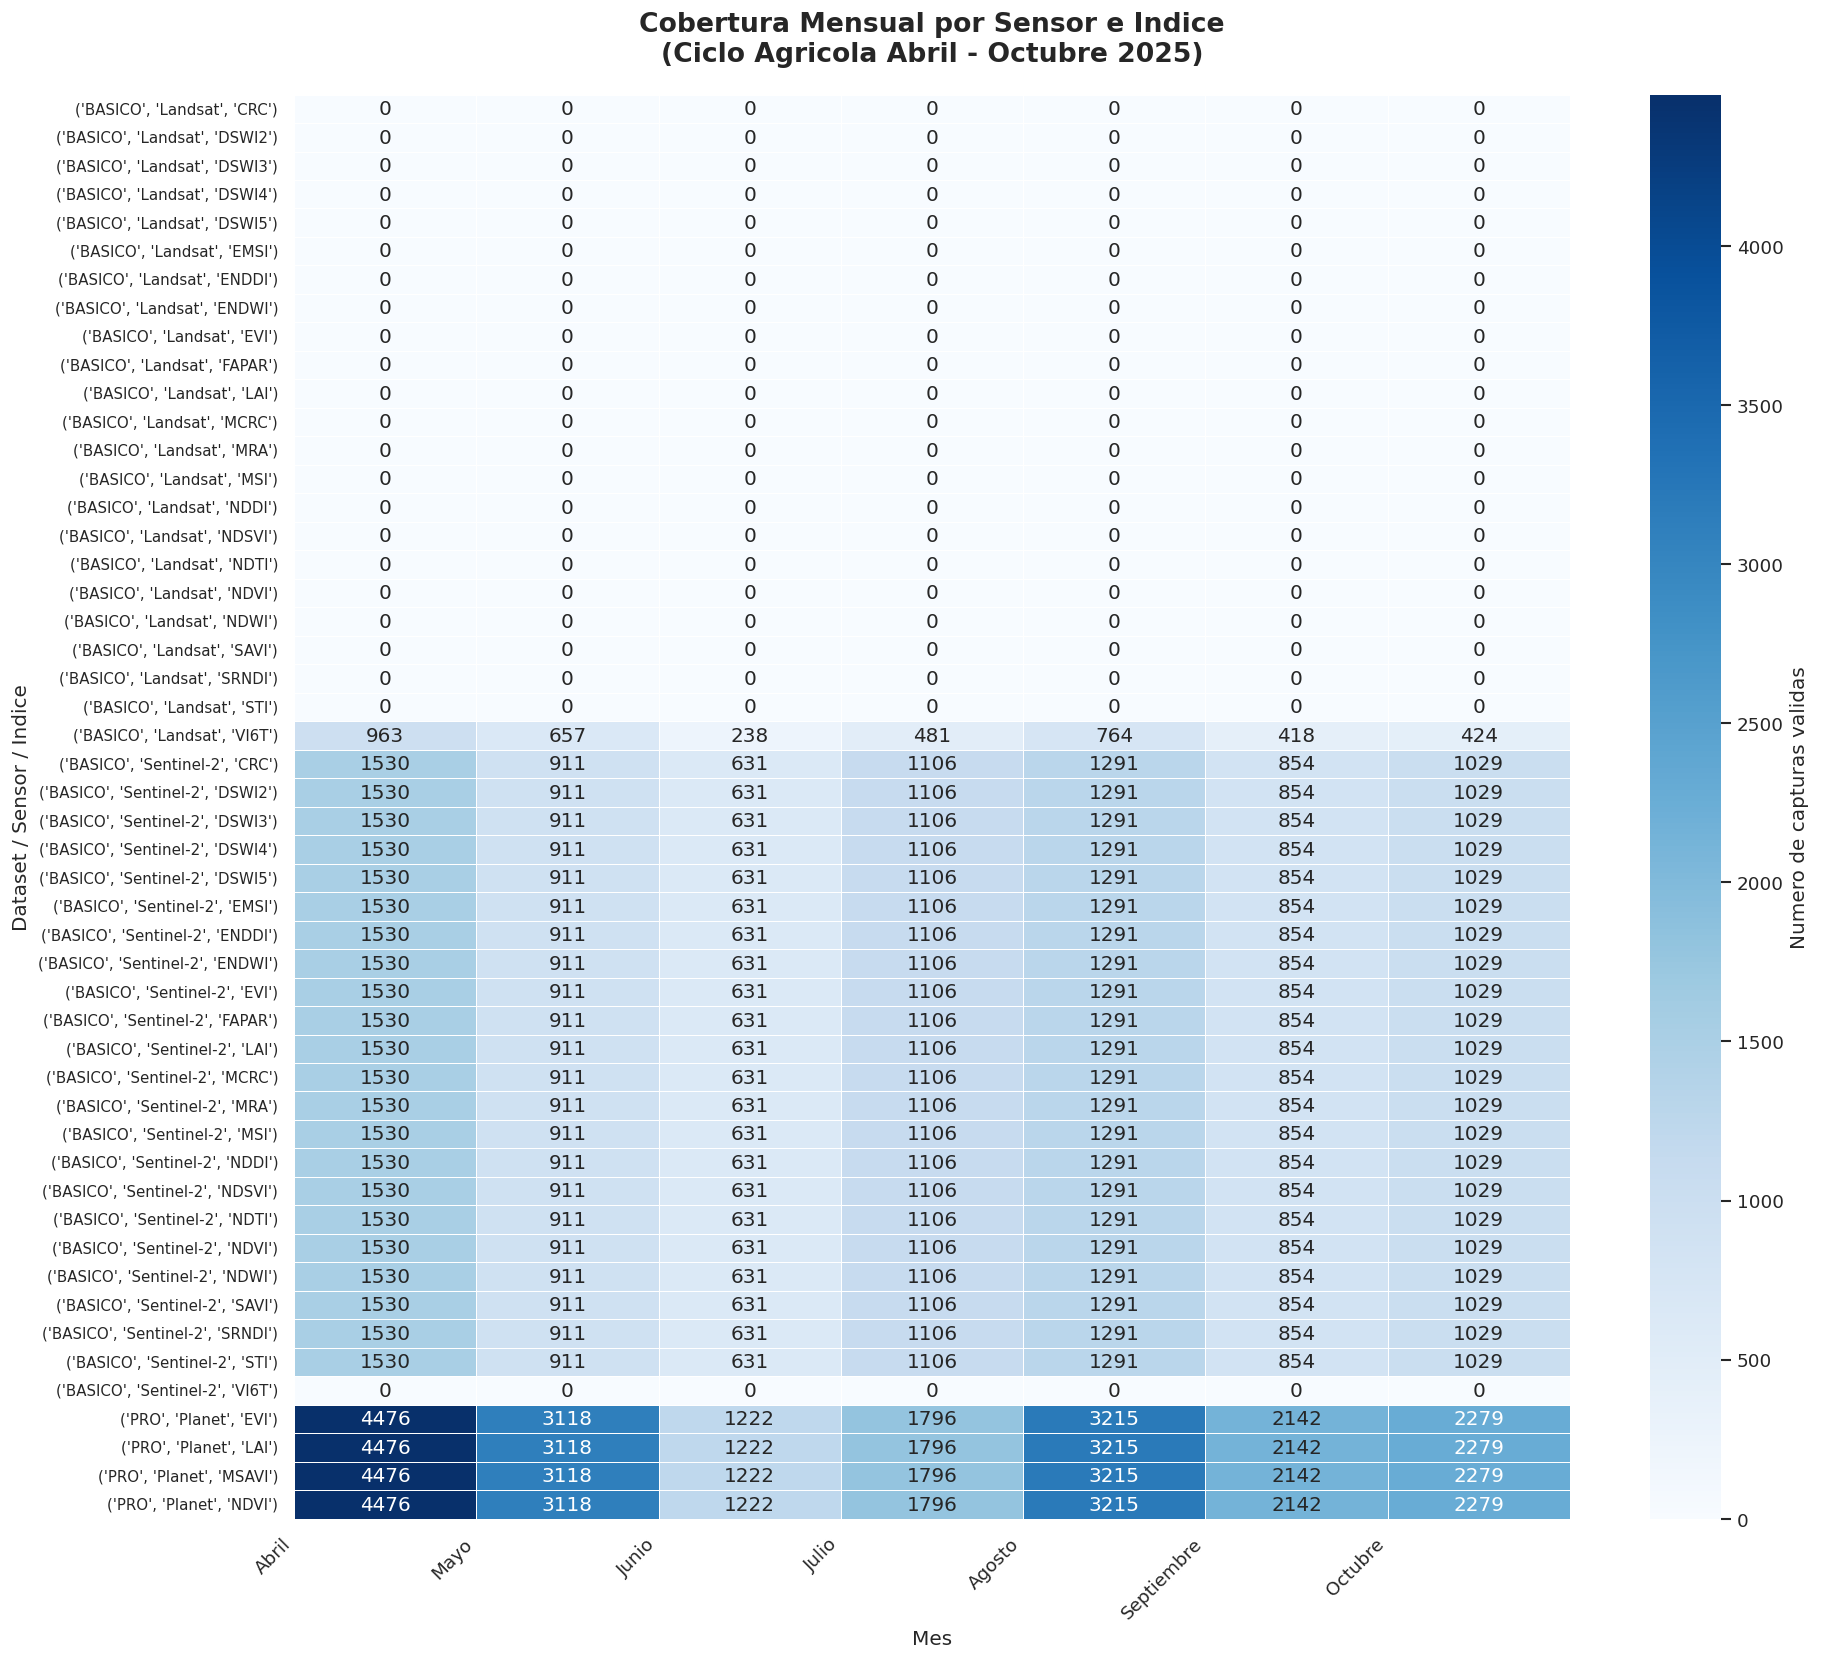


RESUMEN DE COBERTURA:

   BASICO / Landsat:
   - Indices disponibles:       23
   - Total de capturas validas: 3,945
      Abril: 963 capturas
      Mayo: 657 capturas
      Junio: 238 capturas
      Julio: 481 capturas
      Agosto: 764 capturas
      Septiembre: 418 capturas
      Octubre: 424 capturas

   BASICO / Sentinel-2:
   - Indices disponibles:       23
   - Total de capturas validas: 161,744
      Abril: 33,660 capturas
      Mayo: 20,042 capturas
      Junio: 13,882 capturas
      Julio: 24,332 capturas
      Agosto: 28,402 capturas
      Septiembre: 18,788 capturas
      Octubre: 22,638 capturas

   PRO / Planet:
   - Indices disponibles:       4
   - Total de capturas validas: 72,992
      Abril: 17,904 capturas
      Mayo: 12,472 capturas
      Junio: 4,888 capturas
      Julio: 7,184 capturas
      Agosto: 12,860 capturas
      Septiembre: 8,568 capturas
      Octubre: 9,116 capturas

EXPORTACION DE ARTEFACTOS DE LA LIBRETA 01
[OK] Guardado: /content/drive/MyDrive/Reto

In [10]:
# ============================================================
# 9. MAPA DE CALOR DE COBERTURA MENSUAL Y EXPORTACION
# ============================================================
print("=" * 60)
print("MAPA DE CALOR DE COBERTURA MENSUAL POR SENSOR E INDICE")
print("=" * 60)

def calcular_cobertura_mensual(df):
    """Calcula la cobertura mensual agrupando por sensor e indice."""
    sufijos = ['_promedio', '_std', '_min', '_max']
    columnas_base = []
    for col in df.columns:
        for suf in sufijos:
            if suf in col:
                base = col.replace(suf, '')
                if base not in columnas_base and base != 'porcentaje_nubosidad':
                    columnas_base.append(base)
                break

    resultados = []
    for sensor in df['sensor'].unique():
        g = df[df['sensor'] == sensor]
        for indice in columnas_base:
            col_prom = f'{indice}_promedio'
            if col_prom in g.columns:
                capturas_mes = g.groupby('mes')[col_prom].apply(
                    lambda x: x.notna().sum()
                )
                for mes in MESES:
                    n_capturas = capturas_mes.get(mes, 0)
                    resultados.append({
                        'sensor': sensor,
                        'indice': indice.upper(),
                        'mes': mes,
                        'n_capturas': n_capturas
                    })

    return pd.DataFrame(resultados)

cobertura_basico = calcular_cobertura_mensual(df_basico_ventana)
cobertura_pro = calcular_cobertura_mensual(df_pro_ventana)

cobertura_basico['dataset'] = 'BASICO'
cobertura_pro['dataset'] = 'PRO'
cobertura_combinada = pd.concat([cobertura_basico, cobertura_pro], ignore_index=True)

matriz_cobertura = cobertura_combinada.pivot_table(
    values='n_capturas',
    index=['dataset', 'sensor', 'indice'],
    columns='mes',
    aggfunc='sum',
    fill_value=0
).reindex(columns=MESES)

etiquetas_meses = [f'{m}' for m in NOMBRES_MESES]

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(
    matriz_cobertura,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Numero de capturas validas'},
    ax=ax
)

ax.set_xticks(range(len(etiquetas_meses)))
ax.set_xticklabels(etiquetas_meses, rotation=45, ha='right')
ax.set_yticklabels([f'{idx}' for idx in matriz_cobertura.index], rotation=0, fontsize=9)
ax.set_title('Cobertura Mensual por Sensor e Indice\n(Ciclo Agricola Abril - Octubre 2025)', fontsize=16, pad=20)
ax.set_xlabel('Mes', fontsize=12)
ax.set_ylabel('Dataset / Sensor / Indice', fontsize=12)

plt.tight_layout()
guardar_figura(fig, '01_mapa_cobertura_mensual.png', '01_calidad')
guardar_figura(fig, '01_mapa_cobertura_mensual.png', 'reports')
plt.show()

print("\nRESUMEN DE COBERTURA:")
for (dataset, sensor), grupo in cobertura_combinada.groupby(['dataset', 'sensor']):
    indices = grupo['indice'].unique()
    total_capturas = grupo['n_capturas'].sum()
    print(f"\n   {dataset} / {sensor}:")
    print(f"   - Indices disponibles:       {len(indices)}")
    print(f"   - Total de capturas validas: {total_capturas:,}")
    por_mes = grupo.groupby('mes')['n_capturas'].sum()
    for mes in MESES:
        n = por_mes.get(mes, 0)
        mes_nombre = NOMBRES_MESES[MESES.index(mes)]
        print(f"      {mes_nombre}: {n:,} capturas")

# --- Exportacion de artefactos de la Libreta 01 ---
print("\n" + "=" * 60)
print("EXPORTACION DE ARTEFACTOS DE LA LIBRETA 01")
print("=" * 60)
guardar_csv(df_maestro, 'y_rendimiento.csv', '01_calidad')
guardar_csv(df_geo, 'parcelas_geografia_validada.csv', '01_calidad')
guardar_csv(cobertura_combinada, 'cobertura_mensual_sensores.csv', '01_calidad')

resumen_libreta01 = {
    'version': '1.0-calidad-y-contexto',
    'ventana_temporal': {'inicio': INICIO, 'fin': FIN},
    'n_parcelas_totales': int(len(df_maestro)),
    'n_entrenamiento': int(len(df_entrenamiento)),
    'n_prediccion': int(len(df_prediccion)),
    'estados': df_geo['Estado'].value_counts().to_dict(),
    'municipios': df_geo['Municipio'].value_counts().to_dict(),
    'capturas_ventana_basico': int(len(df_basico_ventana)),
    'capturas_ventana_pro': int(len(df_pro_ventana)),
    'indices_basico': indices_basico,
    'indices_pro': indices_pro,
}
guardar_json(resumen_libreta01, 'resumen_libreta01.json', '01_calidad')
listar_archivos('01_calidad')
print("\n[OK] LIBRETA 01 COMPLETADA")